In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))  # notebook runs from notebooks/
from data import CODED, FEATURES, GEO_WIDTH, NUMERIC, TARGET, TEXT, load

pd.set_option("display.max_columns", 60, "display.width", 200)
TRAIN_COLOR, TEST_COLOR = "#2a78d6", "#eb6834"  # colour-blind-safe pair, used in every figure

train, test = load()
train.shape, test.shape

((105000, 58), (45000, 57))

## A. Target

In [4]:
counts = train[TARGET].value_counts().rename(index={1: "accepted", 0: "denied"})
pd.DataFrame({"rows": counts, "share": (counts / len(train)).round(4)})

,rows,share
accepted,,
accepted,89244,0.8499
denied,15756,0.1501


## Helpers

In [ ]:
MUTED, GRID = "#8a8984", "#e6e5e0"
OVERALL = train[TARGET].mean()

FLAG = {"1": "yes", "2": "no", "1111": "exempt"}
SCORE = {"1": "Equifax Beacon 5.0", "2": "Experian Fair Isaac", "3": "FICO Classic 04",
         "4": "FICO Classic 98", "5": "VantageScore 2.0", "6": "VantageScore 3.0",
         "7": "more than one model", "8": "other model", "9": "not applicable",
         "10": "no co-applicant", "1111": "exempt"}
LABELS = {
    "loan_type": {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA RHS/FSA"},
    "lien_status": {"1": "first lien", "2": "subordinate lien"},
    "occupancy_type": {"1": "principal residence", "2": "second residence", "3": "investment"},
    "construction_method": {"1": "site-built", "2": "manufactured"},
    "preapproval": {"1": "requested", "2": "not requested"},
    "submission_of_application": {"1": "direct to institution", "2": "not direct", "3": "n/a", "1111": "exempt"},
    "initially_payable_to_institution": {"1": "payable to institution", "2": "not payable", "3": "n/a", "1111": "exempt"},
    "aus-1": {"1": "DU (Fannie Mae)", "2": "LP/LPA (Freddie Mac)", "3": "TOTAL (FHA)", "4": "GUS (USDA)",
              "5": "other", "6": "not applicable", "7": "[?]", "1111": "exempt"},
    "applicant_credit_score_type": SCORE,
    "co-applicant_credit_score_type": SCORE,
    **{c: FLAG for c in ["reverse_mortgage", "open-end_line_of_credit", "business_or_commercial_purpose",
                         "negative_amortization", "interest_only_payment", "balloon_payment",
                         "other_nonamortizing_features"]},
}


def labelled(col, df=None):
    """Column as strings 'code: meaning' (meaning from LABELS when known)."""
    s = (train if df is None else df)[col].astype("string")
    names = LABELS.get(col, {})
    return s.map(lambda v: f"{v}: {names.get(v, '[?]')}" if names else v, na_action="ignore")


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    # np.minimum/maximum: at p = 0 or 1 rounding can put a bound a hair past p
    return np.minimum(centre - half, p), np.maximum(centre + half, p)


def rate_table(key, y=None):
    """Accept rate per level of "key" (Series aligned with train); missing = its own level."""
    y = train[TARGET] if y is None else y
    key = key.astype("string").fillna("missing")
    t = y.groupby(key).agg(n="size", k="sum")
    t["share"] = t.n / t.n.sum()
    t["rate"] = t.k / t.n
    t["lo"], t["hi"] = wilson(t.k, t.n)
    return t


def style(ax, grid="x"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def plot_rates(ax, t, title, order=None):
    """Accept rate per level with 95% CI; dashed line = overall rate. Sorted by n unless "order"."""
    t = t.reindex(order).dropna(subset=["n"]) if order is not None else t.sort_values("n", ascending=False)
    y = np.arange(len(t))
    ax.errorbar(t.rate, y, xerr=[t.rate - t.lo, t.hi - t.rate], fmt="o", ms=5,
                color=TRAIN_COLOR, elinewidth=1.5)
    ax.axvline(OVERALL, color=MUTED, ls="--", lw=1)
    ax.set_yticks(y, [f"{i}  (n={int(n):,})" for i, n in zip(t.index, t.n)], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.02)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("accept rate, 95% CI  (dashed = overall 0.85)", fontsize=8)
    style(ax)


def rate_grid(cols, ncols=2, width=15, row_h=None):
    """One accept-rate panel per column, codes labelled."""
    nrows = int(np.ceil(len(cols) / ncols))
    tables = [rate_table(labelled(c)) for c in cols]
    row_h = row_h or max(len(t) for t in tables) * 0.28 + 1.0
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, row_h * nrows), squeeze=False)
    for ax, c, t in zip(axes.flat, cols, tables):
        plot_rates(ax, t, c)
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    fig.tight_layout()

## B. Money: "loan_amount", "property_value", "income"

Log scale, because the raw scale is unreadable (loan_amount goes from 5k to 375M). income is in thousands in the raw data, so it is multiplied by 1,000 here to share the dollar axis.

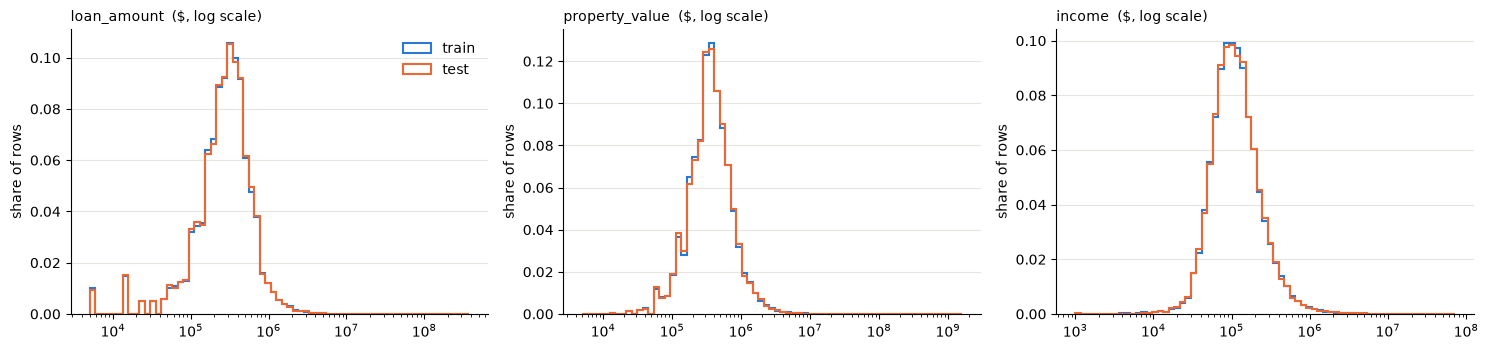

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, ["loan_amount", "property_value", "income"]):
    unit = 1000 if c == "income" else 1
    tr, te = train[c] * unit, test[c] * unit
    tr, te = tr[tr > 0], te[te > 0]
    bins = np.logspace(np.log10(min(tr.min(), te.min())), np.log10(max(tr.max(), te.max())), 70)
    # weights => each bar = share of rows, comparable between train (105k) and test (45k)
    ax.hist(tr, bins=bins, weights=np.ones(len(tr)) / len(tr), histtype="step", lw=1.5, color=TRAIN_COLOR, label="train")
    ax.hist(te, bins=bins, weights=np.ones(len(te)) / len(te), histtype="step", lw=1.5, color=TEST_COLOR, label="test")
    ax.set_xscale("log")
    ax.set_title(f"{c}  ($, log scale)", loc="left", fontsize=10)
    ax.set_ylabel("share of rows")
    style(ax, "y")
axes[0].legend(frameon=False)
fig.tight_layout()

All three are roughly log-normal, centred near $300k (loan), $350k (property), $100k (income). Train and test curves are indistinguishable. The comb at the low end of loan_amount is the $10k rounding (B3) seen on a log axis.

We might work on log(value) for any model sensitive to scale (logistic regression). Trees do not need it (splits only use order).

In [36]:
q = [0, 0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]
display(train[["loan_amount", "property_value", "income"]].quantile(q).rename_axis("quantile").map(lambda v: f"{v:,.0f}"))
train.nlargest(8, "loan_amount")[["loan_amount", "property_value", "income", "loan_to_value_ratio",
                                   "debt_to_income_ratio", "derived_loan_product_type", TARGET]]

,loan_amount,property_value,income
quantile,,,
0.000,"5,000","5,000",-657
0.001,"5,000","25,000",0
0.010,"5,000","55,000",4
0.250,"175,000","235,000",70
0.500,"285,000","355,000",107
0.750,"435,000","545,000",169
0.990,"1,615,000","2,340,700",828
0.999,"5,505,080","8,461,260","2,832"
1.000,"375,005,000","1,581,075,000","71,000"


,loan_amount,property_value,income,loan_to_value_ratio,debt_to_income_ratio,derived_loan_product_type,accepted
98639,375005000.0,626705000.0,NaN,59.800,NaN,Conventional:First Lien,1
89066,333965000.0,405405000.0,NaN,727.680,NaN,Conventional:First Lien,1
101287,127815000.0,NaN,NaN,NaN,NaN,Conventional:First Lien,1
91836,112005000.0,NaN,NaN,NaN,NaN,Conventional:First Lien,0
59098,91005000.0,118205000.0,NaN,40.400,NaN,Conventional:First Lien,1
104425,88765000.0,117505000.0,NaN,75.543,NaN,Conventional:First Lien,1
28732,85005000.0,NaN,NaN,NaN,NaN,Conventional:First Lien,0
2804,75005000.0,NaN,NaN,NaN,NaN,Conventional:First Lien,0


The largest loan ($375M) has a $627M property and a 60% LTV, so it looks like a commercial loan. Large loans have **no income** (NaN), consistent with non-natural-person borrowers. 1% of loans are the $5k minimum.

We do not delete extremes. After a log they are ~6 units from the median. For the linear model, a log is enough.
Clipping thresholds would be an extra arbitrary choice.

Q. How are the amounts rounded?

In [8]:
pd.DataFrame({
    "loan_amount: v mod 10000 == 5000": [(train.loan_amount % 10000 == 5000).mean(), (test.loan_amount % 10000 == 5000).mean()],
    "property_value: v mod 10000 == 5000": [(train.property_value.dropna() % 10000 == 5000).mean(), (test.property_value.dropna() % 10000 == 5000).mean()],
    "income: integer (whole $k)": [(train.income.dropna() % 1 == 0).mean(), (test.income.dropna() % 1 == 0).mean()],
}, index=["train", "test"]).T.round(4)

,train,test
loan_amount: v mod 10000 == 5000,1.0,1.0
property_value: v mod 10000 == 5000,1.0,1.0
income: integer (whole $k),1.0,1.0


Every 100% of "loan_amount" and "property_value" are $10k midpoints (...5,000), 100% of incomes are whole $k.

Any ratio built from them carries rounding error: up to ±$5k per argument, negligible at $400k and large at $25k. However, must take it account

Q. what is the shape of the accept rate along each money variable: flat, straight, or curved?

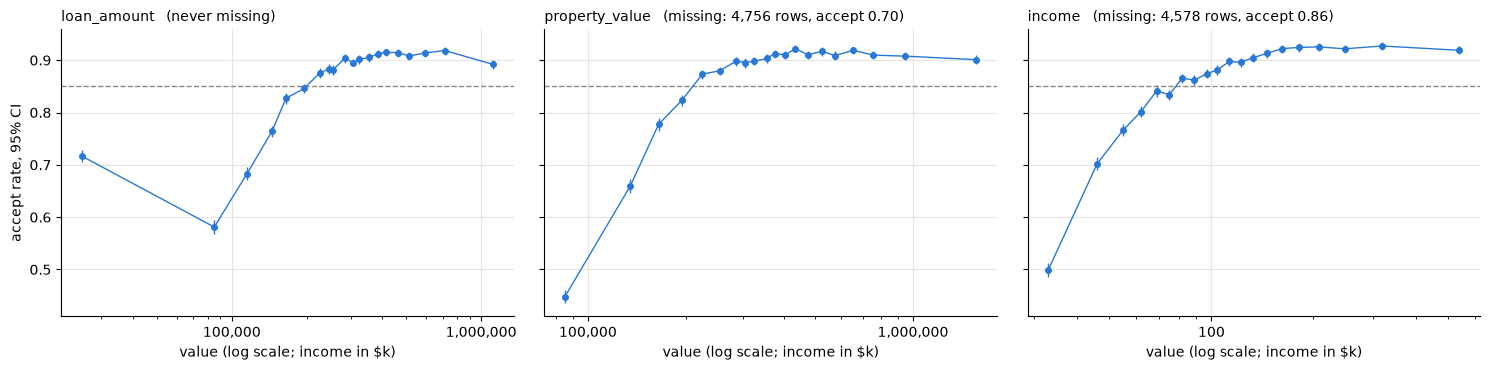

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, c in zip(axes, ["loan_amount", "property_value", "income"]):
    s = train[c].where(train[c] > 0)          # log axis: non-positive handled in B5
    bins = pd.qcut(s, 20, duplicates="drop")
    g = train.groupby(bins, observed=True).agg(x=(c, "median"), n=(TARGET, "size"), k=(TARGET, "sum"))
    lo, hi = wilson(g.k, g.n)
    r = g.k / g.n
    ax.errorbar(g.x, r, yerr=[r - lo, hi - r], fmt="o-", ms=4, lw=1, color=TRAIN_COLOR)
    n_miss = train[c].isna().sum()
    note = f"missing: {n_miss:,} rows, accept {train[TARGET][train[c].isna()].mean():.2f}" if n_miss else "never missing"
    ax.axhline(OVERALL, color=MUTED, ls="--", lw=1)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{c}   ({note})", loc="left", fontsize=10)
    ax.set_xlabel("value (log scale; income in $k)")
    style(ax, "both")
axes[0].set_ylabel("accept rate, 95% CI")
fig.tight_layout()

Non-linear, saturating curves. Acceptance rises steeply with loan amount, property value and income, then plateaus (~0.91) above roughly $250k loan / $300k property / $150k income. "loan_amount" is even non-monotone at the bottom (the very small loans do better than the ~$85k ones). Missing "property_value" means accept 0.70 (vs 0.86).

For logistic regression a straight line in log(value) is **not** enough. We might use splines (or bins) on the log scale and keep a missing flag for "property_value".

Q. which are the rows with income missing, negative or zero?

In [10]:
inc = train.income
group = pd.Series(np.select([inc.isna(), inc < 0, inc == 0], ["missing", "negative", "zero"], "positive"), index=train.index)
t = rate_table(group)
t["test_share"] = pd.Series(np.select([test.income.isna(), test.income < 0, test.income == 0],
                                      ["missing", "negative", "zero"], "positive")).value_counts(normalize=True)
t[["n", "share", "test_share", "rate", "lo", "hi"]].round(4)

,n,share,test_share,rate,lo,hi
missing,4578,0.0436,0.0449,0.8587,0.8483,0.8685
negative,28,0.0003,0.0004,0.0000,0.0000,0.1206
positive,99468,0.9473,0.9463,0.8523,0.8501,0.8545
zero,926,0.0088,0.0084,0.5778,0.5457,0.6092


- Income = 0: 926 rows, accept **0.58**. 
- Income < 0: 28 rows, accept **0 of 28** (CI up to 0.12). 
- Missing income: 4.4%, accept 0.86 (normal).

We keep zero and negative incomes as information. We add flag "income <= 0". Missing income is not informative on its own (0.86 ≈ 0.85).

## C. Ratios: loan-to-value and debt-to-income

Q. does the reported "loan_to_value_ratio" agree with loan_amount / property_value?

If not, which one is "right", and does disagreement carry information?

rows with both: 92,643   |diff| <= 5: 0.906   |diff| > 20: 0.055


,n,rate,lo,hi
|diff| <= 5,83980,0.901,0.899,0.903
|diff| > 5,8663,0.812,0.804,0.820


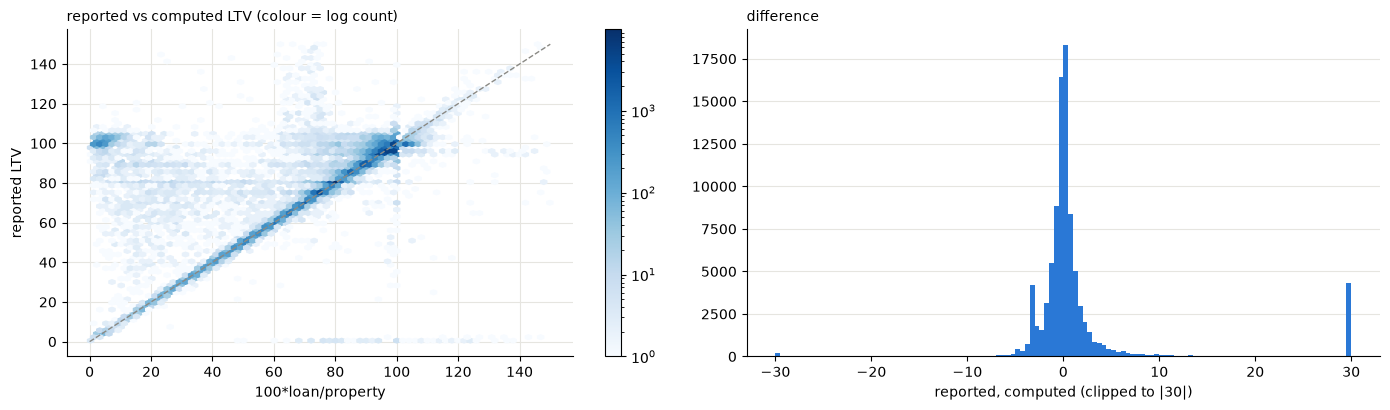

In [38]:
computed = 100 * train.loan_amount / train.property_value
reported = train.loan_to_value_ratio
both = reported.notna() & computed.notna()
diff = (reported - computed)[both]

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.2))
m = both & reported.between(0, 150) & computed.between(0, 150)
hb = a.hexbin(computed[m], reported[m], gridsize=75, bins="log", cmap="Blues", mincnt=1)
a.plot([0, 150], [0, 150], color=MUTED, lw=1, ls="--")
a.set_xlabel("100*loan/property")
a.set_ylabel("reported LTV")
a.set_title("reported vs computed LTV (colour = log count)", loc="left", fontsize=10)
fig.colorbar(hb, ax=a)
b.hist(diff.clip(-30, 30), bins=120, color=TRAIN_COLOR)
b.set_xlabel("reported, computed (clipped to |30|)"); b.set_title("difference", loc="left", fontsize=10)
style(a, "both"); style(b, "y")
fig.tight_layout()
print(f"rows with both: {both.sum():,}   |diff| <= 5: {(diff.abs() <= 5).mean():.3f}   "
      f"|diff| > 20: {(diff.abs() > 20).mean():.3f}")
agree = pd.Series(np.where(diff.abs() <= 5, "|diff| <= 5", "|diff| > 5"), index=diff.index)
rate_table(agree, train.loc[diff.index, TARGET])[["n", "rate", "lo", "hi"]].round(3)

Left: reported vs computed (plausible range 0-150 only). Right: the difference, reported and computed.

90.6% of rows agree within 5 points. The disagreements are structured. Horizontal bands at reported =80 and =100 while the computed ratio is small. That is the signature of a **combined** LTV (all liens on the property). Rows that disagree by > 5 points are accepted less (0.81 vs 0.90).

We keep both reported and computed LTV, and their difference.

Q. how does the accept rate move with reported LTV?

Bins of width 5 up to 125 (underwriting thresholds such as 80, 90, 95 sit on multiples of 5), then one ">125" bin and missing.

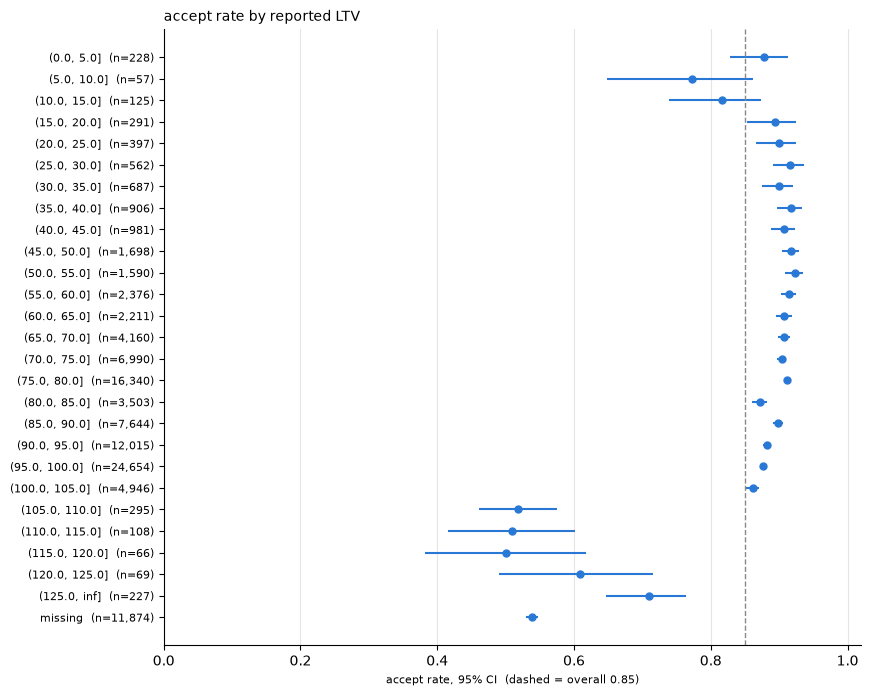

In [12]:
ltv = train.loan_to_value_ratio
edges = list(range(0, 130, 5)) + [np.inf]
b = pd.cut(ltv, edges, right=True).astype("string").fillna("missing")
t = rate_table(b)
order = [str(i) for i in pd.cut(pd.Series(edges[1:]) - 0.1, edges).cat.categories] + ["missing"]
fig, ax = plt.subplots(figsize=(9, 8))
plot_rates(ax, t, "accept rate by reported LTV", order=order)

Flat at ~0.90 from 15 to 100, then a cliff above 105 (~0.5). Missing LTV (11.3%) giving **0.54**, one of the strongest single signals.

Trees handle threshold natively. The linear model needs a knot / bin at ~100. Missing LTV must stay visible to the model (flag)

debt_to_income_ratio,<20%,20%-<30%,30%-<36%,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50%-60%,>60%,missing
n,4650,12401,13624,2746,2978,3073,3403,3500,3655,3875,3657,4165,3511,3554,3762,3938,5793,10445,4591,7679
share,0.044,0.118,0.13,0.026,0.028,0.029,0.032,0.033,0.035,0.037,0.035,0.04,0.033,0.034,0.036,0.038,0.055,0.099,0.044,0.073
test_share,0.045,0.118,0.135,0.027,0.027,0.028,0.032,0.032,0.032,0.036,0.036,0.038,0.033,0.035,0.034,0.039,0.057,0.098,0.045,0.074
rate,0.781,0.897,0.917,0.917,0.921,0.921,0.923,0.917,0.915,0.908,0.923,0.925,0.909,0.914,0.902,0.902,0.92,0.754,0.12,0.822


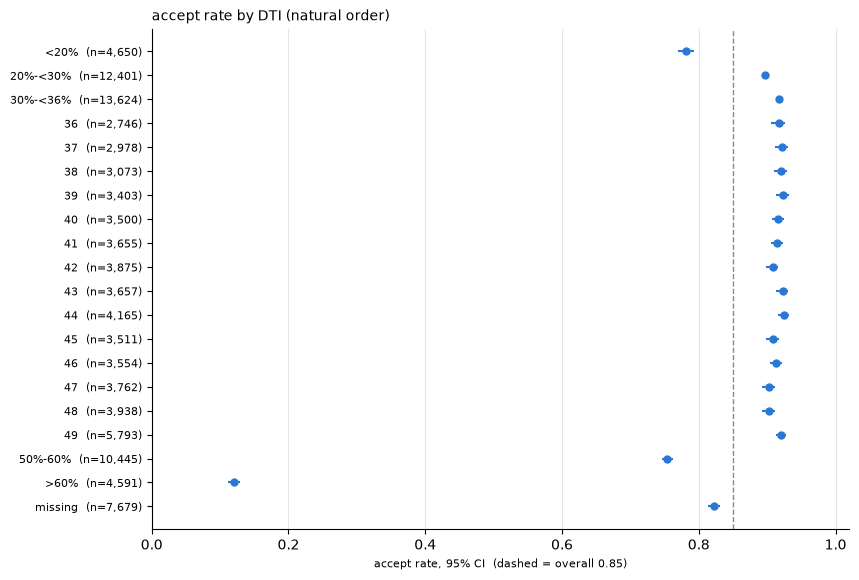

In [13]:
dti_order = ["<20%", "20%-<30%", "30%-<36%"] + [str(i) for i in range(36, 50)] + ["50%-60%", ">60%", "missing"]
t = rate_table(train.debt_to_income_ratio)
t["test_share"] = test.debt_to_income_ratio.astype("string").fillna("missing").value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
plot_rates(ax, t, "accept rate by DTI (natural order)", order=dti_order)
t.reindex(dti_order)[["n", "share", "test_share", "rate"]].round(3).T

- Flat at ~0.91 from 20 to 49%
- 50-60% with 0.75 
- \>60% with 0.12. 
- <20% with 0.78, lower than the middle (U-shape). 

The <20% group has much higher median income ($181k vs $105k), so it is not a group of poor applicants. 

**Hypothesis** to test: very low DTI flags unusual files (e.g. investors, incomplete income documentation). Missing DTI means 0.82. Train and test shares identical.

Parse into an ordered variable: numeric midpoint + "dti_is_exact" flag + missing flag.

## D. Loan characteristics

Q. which loan characteristics separate accepted from denied, and are any levels too rare to trust?

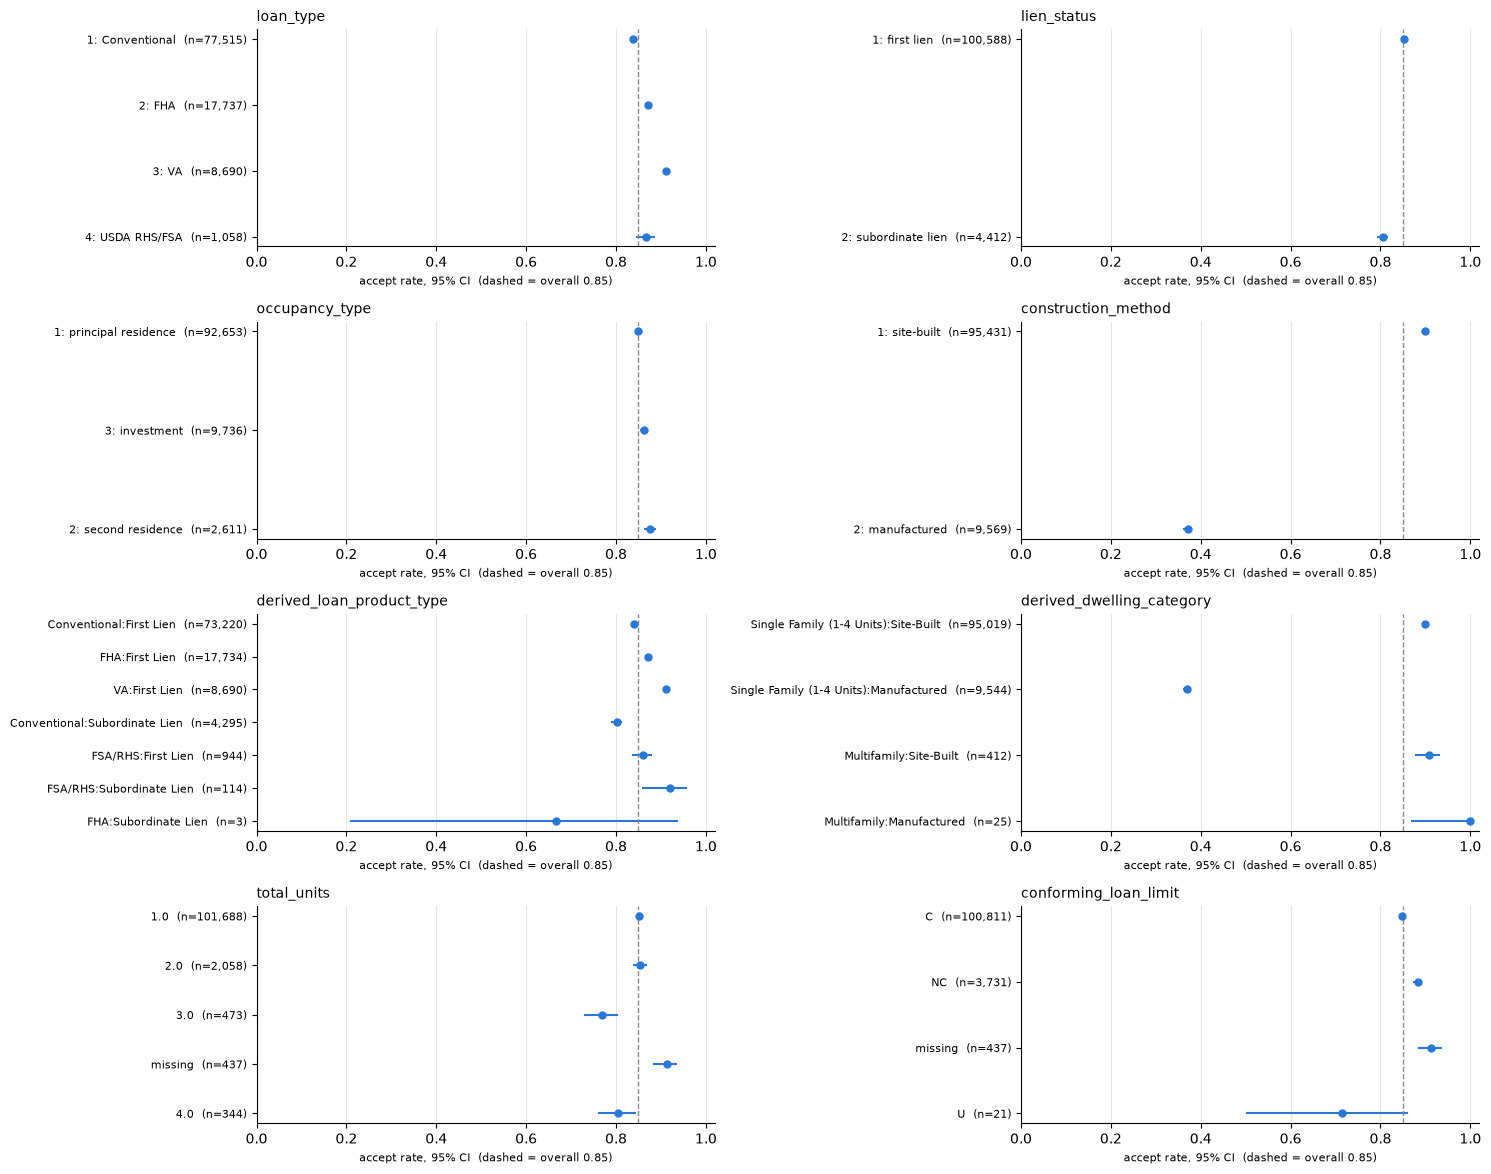

In [14]:
rate_grid(["loan_type", "lien_status", "occupancy_type", "construction_method",
           "derived_loan_product_type", "derived_dwelling_category", "total_units", "conforming_loan_limit"])

The big one is manufactured homes: 0.37 vs 0.90 for site-built (9,569 rows). 

Subordinate liens: 0.80. 

Loan type, occupancy and total units are close to the overall rate. 

"derived_dwelling_category" = construction method * units (redundant). 

"conforming_loan_limit" = U: 21 rows, "FHA:Subordinate Lien": 3 rows, too rare to read.

Manufactured homes are a distinct lending segment. Look at interactions *within* it (D2, F2). Rare levels (< 100 rows) get the rare-level policy.

Q. "loan_term" is dominated by 360 months: what else is there, and does it matter?

distinct terms: 227 | share 360: 0.814 | terms > 360: 1056 | terms < 12: 146


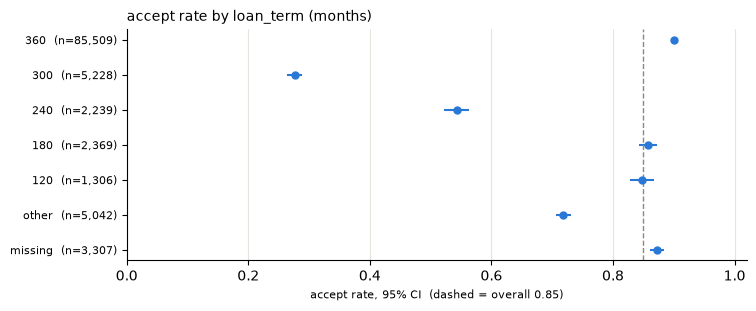

In [15]:
term = train.loan_term
common = [360, 300, 240, 180, 120]
group = term.map(lambda v: f"{v:.0f}" if v in common else ("missing" if pd.isna(v) else "other")).astype("string")
t = rate_table(group)
fig, ax = plt.subplots(figsize=(8, 3))
plot_rates(ax, t, "accept rate by loan_term (months)", order=[str(c) for c in common] + ["other", "missing"])
print("distinct terms:", term.nunique(), "| share 360:", round((term == 360).mean(), 3),
      "| terms > 360:", int((term > 360).sum()), "| terms < 12:", int((term < 12).sum()))

300-month terms => 0.28, 240 => 0.54, although 360 => 0.90. This is mostly D1 again as 89% of 300-month loans are manufactured homes (49% of 240-month, 2% of 360-month).

"loan_term" is largely a proxy for the manufactured-home segment. Keep it (trees will split the two), but do not read its effect alone. 1,056 terms > 360 and 146 terms < 12 months: check against the dictionary before calling them errors.

The yes/no loan features (reverse mortgage, open-end line, business purpose, negative amortization,
interest-only, balloon, other non-amortizing): informative, or almost constant?

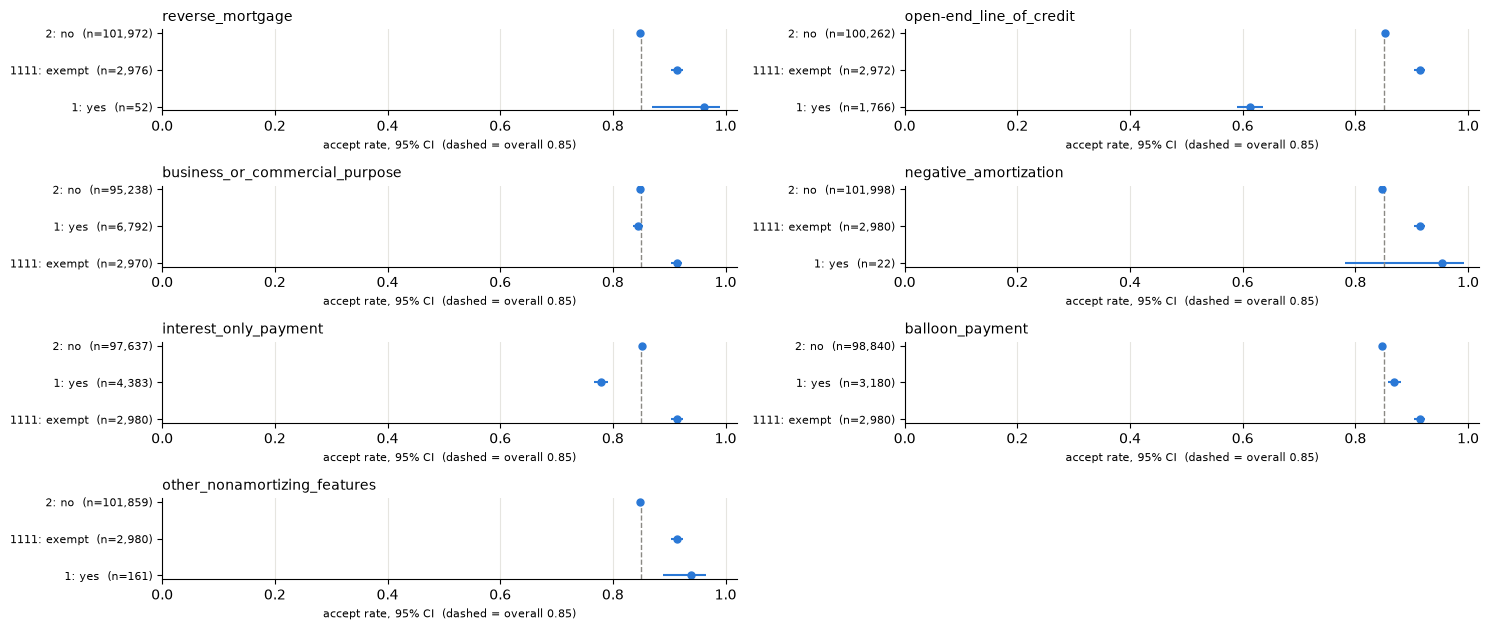

In [16]:
rate_grid(["reverse_mortgage", "open-end_line_of_credit", "business_or_commercial_purpose", "negative_amortization",
           "interest_only_payment", "balloon_payment", "other_nonamortizing_features"], row_h=1.6)

"open-end_line_of_credit = yes" gives 0.61, and "interest_only = yes" => 0.78. The others are rare (reverse mortgage 52, negative amortization 22) or flat (business purpose). The "1111: exempt" level has the same accept rate (0.91) and the same ~2,980 rows in every column.

Keep open-end and interest-only. The rare flags add little but cost nothing to trees. The "1111" level is one row-level fact repeated 14 times.

## E. leakage suspects

Do these fields describe the applicant or the outcome of processing the application?

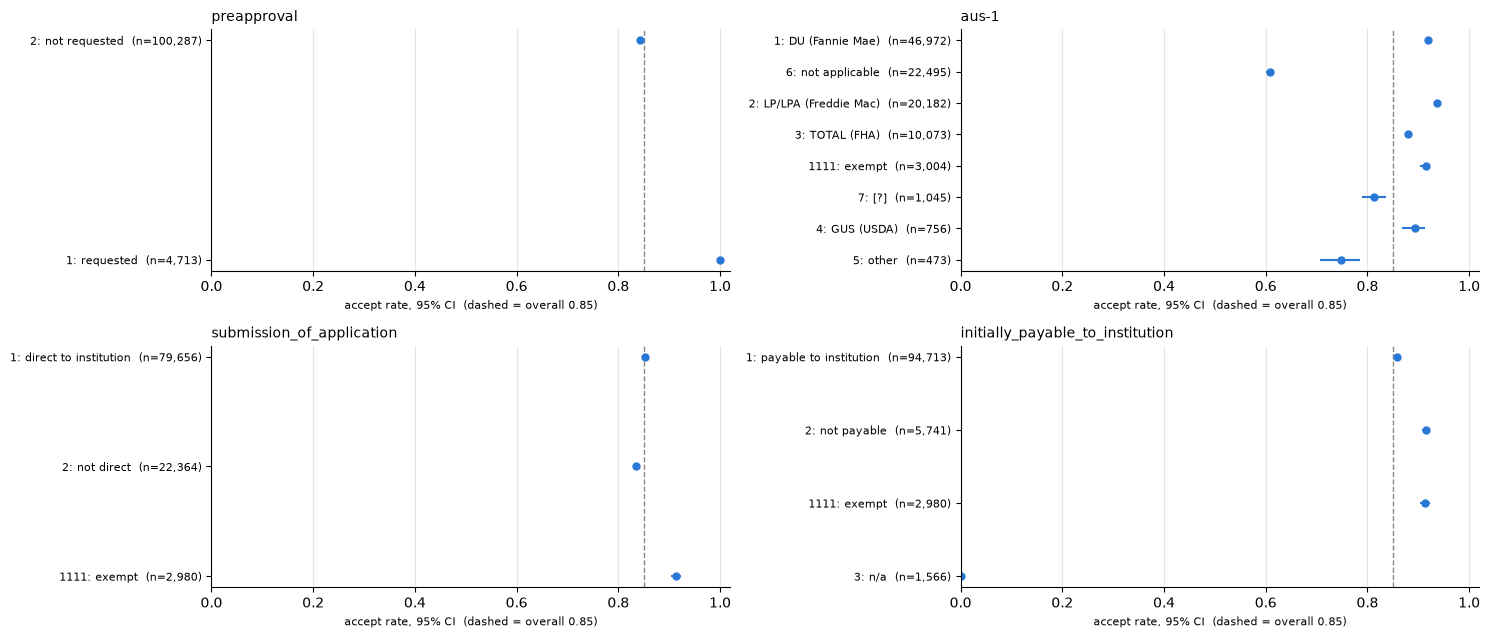

In [17]:
rate_grid(["preapproval", "aus-1", "submission_of_application", "initially_payable_to_institution"])

Two deterministic levels: 
- "preapproval = requested" => **100%** accepted (4,713 rows)
- "initially_payable_to_institution = 3 (n/a)" => **0%** (1,566 rows). 
- "aus-1 = 6" (no automated underwriting) => 0.61 on 22,495 rows.

Leakage suspects... If "n/a" is only filled for applications that were not originated, the field is recorded because of the decision. It would still be present in test (so usable for the competition), but it must be excluded from the fair/clean model and discussed in the report.

"aus-1 = 6" accepts far less often.
Is that about the loan type or something else?

In [18]:
ct = pd.crosstab(labelled("loan_type"), labelled("aus-1"), values=train[TARGET], aggfunc="mean").round(2)
n = pd.crosstab(labelled("loan_type"), labelled("aus-1"))
display(n)
ct

aus-1,1111: exempt,1: DU (Fannie Mae),2: LP/LPA (Freddie Mac),3: TOTAL (FHA),4: GUS (USDA),5: other,6: not applicable,7: [?]
loan_type,,,,,,,,
1: Conventional,2931,33063,18497,113,5,447,21431,1028
2: FHA,42,6783,442,9926,1,13,517,13
3: VA,19,7103,1238,25,0,5,297,3
4: USDA RHS/FSA,12,23,5,9,750,8,250,1


aus-1,1111: exempt,1: DU (Fannie Mae),2: LP/LPA (Freddie Mac),3: TOTAL (FHA),4: GUS (USDA),5: other,6: not applicable,7: [?]
loan_type,,,,,,,,
1: Conventional,0.92,0.92,0.94,0.88,1.00,0.74,0.61,0.82
2: FHA,0.83,0.89,0.81,0.88,0.00,0.85,0.52,0.38
3: VA,0.89,0.93,0.87,0.88,NaN,1.00,0.70,0.67
4: USDA RHS/FSA,0.50,0.74,1.00,0.89,0.89,0.88,0.81,1.00


"aus-1 = 6" is low for every loan type (Conventional 0.61, FHA 0.52, VA 0.70, USDA 0.81), so it is not a loan-type effect. It concentrates in the manufactured segment, manufactured*no AUS => 0.25 (7,573 rows), vs site-built × AUS => 0.92.

The pair (construction method, AUS used) is a strong interaction. It is expected to be learned by trees, to be built explicitly for the linear model.

## F. Credit score type

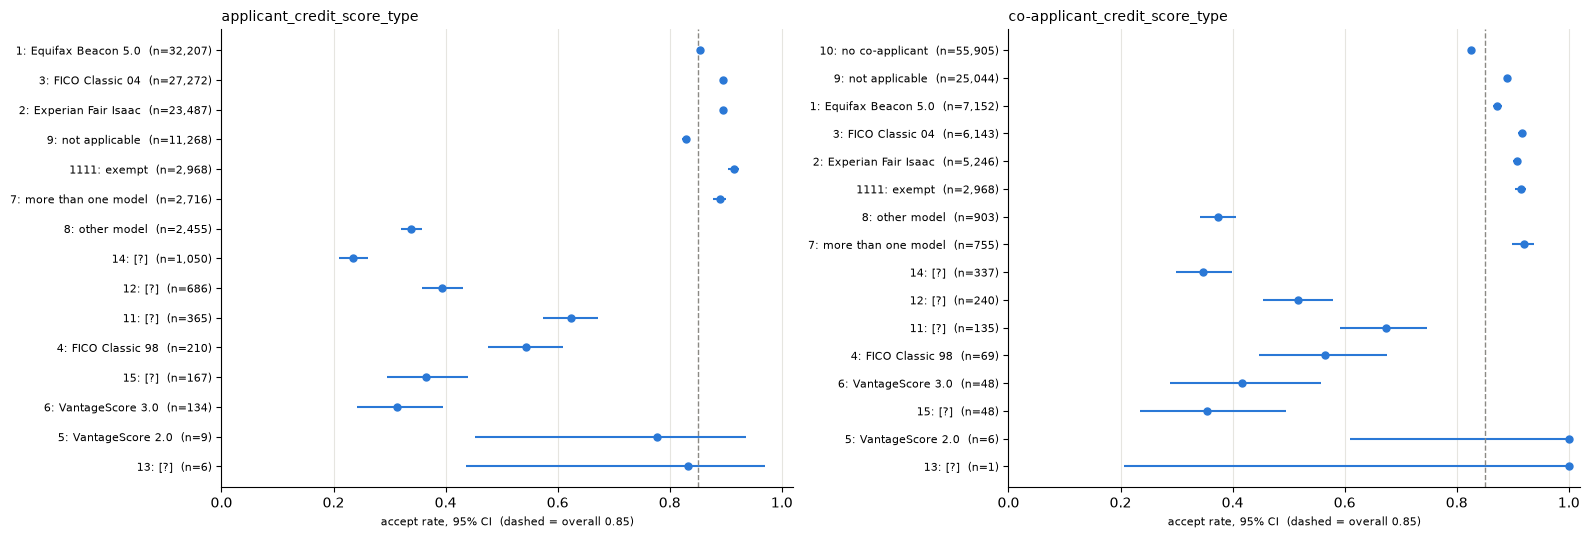

In [19]:
rate_grid(["applicant_credit_score_type", "co-applicant_credit_score_type"], width=16)

Even without any score, the *type* separates strongly: mainstream models (Equifax, Experian, FICO 04, several models) = 0.86-0.90

"8: other model" => **0.34**, codes 14 / 12 / 15 / 6 => 0.23-0.40. **74% of those low-acceptance types are manufactured-home loans** (vs 6% for others). Codes 11-15 are unknown to me.

We keep as categorical. Its signal is partly the manufactured segment again: the report must say "lender/segment practice", not "credit quality".

In [20]:
low = train.applicant_credit_score_type.isin(["8", "14", "12", "15", "6"])
no_aus = train["aus-1"] == "6"
g = pd.Series(np.select([low & no_aus, low & ~no_aus, ~low & no_aus], ["low-type & no AUS", "low-type & AUS", "other type & no AUS"],
                        "other type & AUS"), index=train.index)
rate_table(g)[["n", "share", "rate", "lo", "hi"]].round(3)

,n,share,rate,lo,hi
low-type & AUS,300,0.003,0.937,0.903,0.959
low-type & no AUS,4192,0.040,0.279,0.266,0.293
other type & AUS,82205,0.783,0.916,0.914,0.918
other type & no AUS,18303,0.174,0.683,0.676,0.690


Low-acceptance score type **AND** no AUS => **0.28** (4,192 rows)

Low type with AUS => 0.94 (300 rows)

Mainstream type without AUS => 0.68. 

The two signals overlap heavily but are not the same.

Evidence for one "non-standard / manufactured / no-AUS" segment

## G. Geography

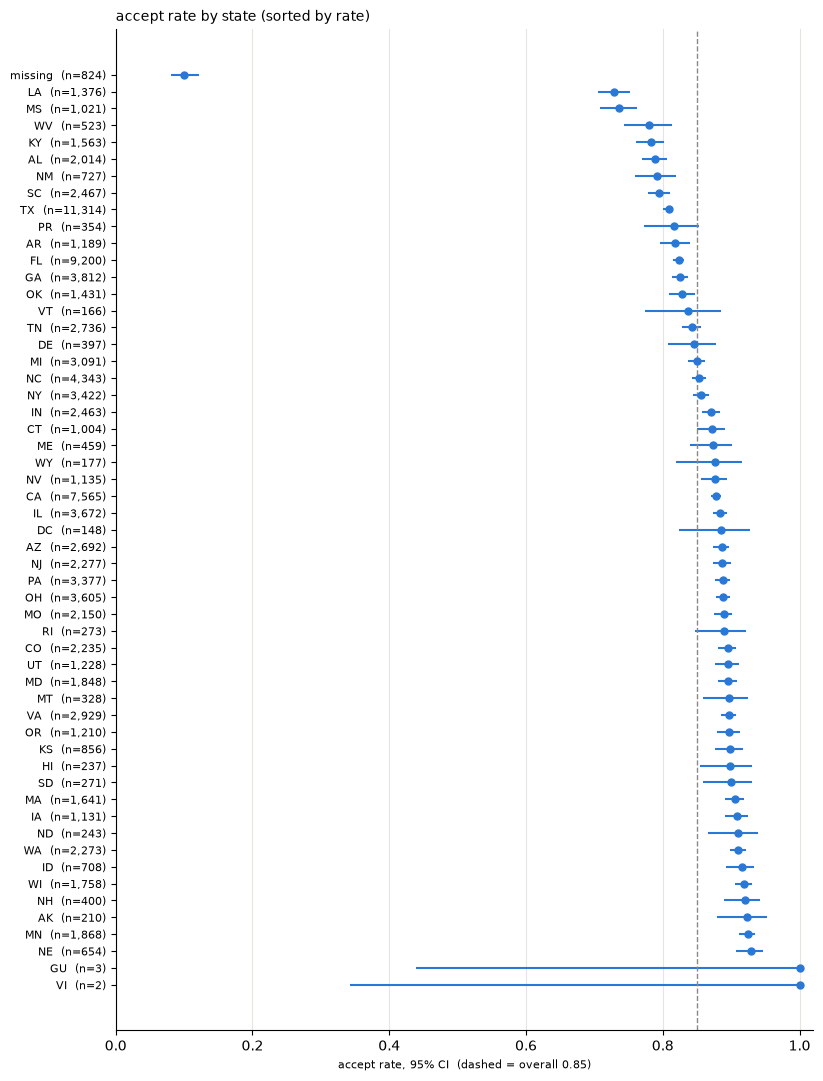

In [21]:
t = rate_table(train.state_code)
fig, ax = plt.subplots(figsize=(9, 13))
plot_rates(ax, t, "accept rate by state (sorted by rate)", order=t.sort_values("rate").index)

States range from ~0.73 (LA, MS) to ~0.93 (NE, MN), well outside the CIs, so real differences; lowest are mostly Southern states. **Missing state > 0.10** (824 rows). GU (3) and VI (2) are too small to read.

State is a useful low-cardinality feature. The missing-state rows are a separate phenomenon (G3).

counties with n >= 30 outside the band: 190 of 687


,counties,rows,share_of_rows
n,,,
1-9,1463,6079,0.058
10-29,748,12488,0.119
30-99,429,23618,0.225
100-999,254,55873,0.532
1000+,4,5603,0.053


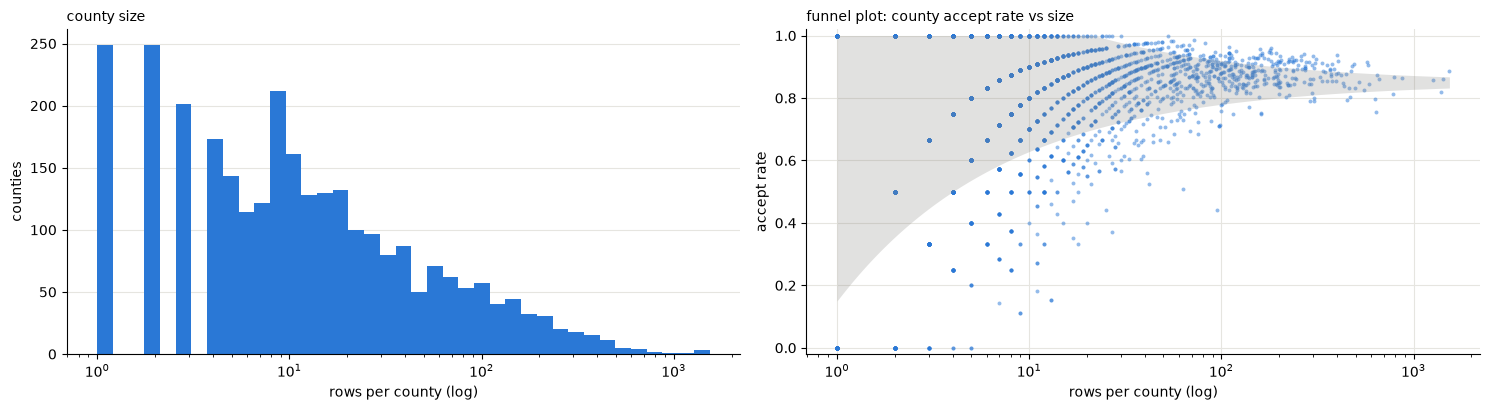

In [22]:
t = rate_table(train.county_code).drop("missing")
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.2))
a.hist(t.n, bins=np.logspace(0, np.log10(t.n.max()), 40), color=TRAIN_COLOR)
a.set_xscale("log"); a.set_xlabel("rows per county (log)"); a.set_ylabel("counties")
a.set_title("county size", loc="left", fontsize=10)
b.scatter(t.n, t.rate, s=8, alpha=0.5, color=TRAIN_COLOR, lw=0)
n_grid = np.logspace(0, np.log10(t.n.max()), 200)
band = 1.96 * np.sqrt(OVERALL * (1 - OVERALL) / n_grid)
b.fill_between(n_grid, OVERALL - band, np.minimum(OVERALL + band, 1), color=MUTED, alpha=0.25, lw=0)
b.set_xscale("log"); b.set_ylim(-0.02, 1.02); b.set_xlabel("rows per county (log)"); b.set_ylabel("accept rate")
b.set_title("funnel plot: county accept rate vs size", loc="left", fontsize=10)
style(a, "y"); style(b, "both")
fig.tight_layout()
sizes = pd.cut(t.n, [0, 9, 29, 99, 999, np.inf], labels=["1-9", "10-29", "30-99", "100-999", "1000+"])
out = (t.n > 29) & ((t.rate - OVERALL).abs() > 1.96 * np.sqrt(OVERALL * (1 - OVERALL) / t.n))
print(f"counties with n >= 30 outside the band: {out.sum()} of {(t.n > 29).sum()}")
pd.DataFrame({"counties": sizes.value_counts(), "rows": t.n.groupby(sizes, observed=True).sum()}).sort_index().assign(
    share_of_rows=lambda d: (d.rows / len(train)).round(3))

- 1,463 counties have < 10 rows (together only 5.8% of rows)
- 58% of rows are in the 258 counties with ≥ 100 rows. 
- Among counties with ≥ 30 rows, 190 of 687 fall outside the pure-noise band (~34 expected by chance), so county effects are real. 

But small countries rates are dominated by noise (the funnel).

Do not feed 2,898 raw levels without shrinkage. Use **smoothed, out-of-fold target encoding** and/or counts. This is also consistent with the LightGBM baseline stopping at ~90 trees (overfitting on high-cardinality categoricals, still a hypothesis).

In [23]:
geo = pd.Series(np.select([train.state_code.isna() & train.county_code.isna(), train.state_code.isna(), train.county_code.isna()],
                          ["state & county missing", "state only missing", "county only missing"], "both present"), index=train.index)
display(rate_table(geo)[["n", "share", "rate", "lo", "hi"]].round(3))
m = geo != "both present"
pd.DataFrame({
    "census tract_population == 0": [(train.tract_population[m] == 0).mean(), (train.tract_population[~m] == 0).mean()],
    "msa == 99999": [(train["derived_msa-md"][m] == "99999").mean(), (train["derived_msa-md"][~m] == "99999").mean()],
    "property_value missing": [train.property_value[m].isna().mean(), train.property_value[~m].isna().mean()],
    "LTV missing": [train.loan_to_value_ratio[m].isna().mean(), train.loan_to_value_ratio[~m].isna().mean()],
    "aus-1 = 6": [(train["aus-1"][m] == "6").mean(), (train["aus-1"][~m] == "6").mean()],
}, index=["geo missing", "geo present"]).T.round(3)

,n,share,rate,lo,hi
both present,103627,0.987,0.858,0.856,0.860
county only missing,549,0.005,0.495,0.454,0.537
state & county missing,790,0.008,0.073,0.057,0.094
state only missing,34,0.000,0.706,0.538,0.832


,geo missing,geo present
census tract_population == 0,0.973,0.008
msa == 99999,0.977,0.134
property_value missing,0.289,0.042
LTV missing,0.446,0.109
aus-1 = 6,0.842,0.206


State **and** county missing: 790 rows, accept **0.07**

County only: 549 rows, 0.50. These rows also have census zeros (97%), MSA 99999 (98%), no AUS (84%) and often missing LTV (45%). They look like applications where **no property was identified**, which are typically denied early.

One flag "property_location_unknown". It is probably a *process* signal (the file stopped early) rather than an applicant property.

In [24]:
msa = pd.Series(np.where(train["derived_msa-md"] == "99999", "99999", "metro area code"), index=train.index)
display(rate_table(msa)[["n", "share", "rate", "lo", "hi"]].round(3))
train.groupby(msa).agg(median_income=("income", "median"), median_loan=("loan_amount", "median"),
                       median_tract_pop=("tract_population", "median"),
                       states=("state_code", "nunique"), counties=("county_code", "nunique"))

,n,share,rate,lo,hi
99999,15200,0.145,0.751,0.744,0.758
metro area code,89800,0.855,0.867,0.864,0.869


,median_income,median_loan,median_tract_pop,states,counties
99999,82.0,185000.0,3543.0,53,1669
metro area code,112.0,305000.0,4683.0,52,1229


"99999" = 15,200 rows spread over 1,669 counties in 53 states, with lower incomes and smaller loans, accept 0.75 vs 0.87. 

It is a real category outside any metro area (rural), not a missing value. But the geo-missing rows of G3 are also "99999".

Keep "99999" as its own level

Separate "rural" (county known) from "location unknown" (county missing) with the G3 flag.

In [25]:
CENSUS = ["tract_population", "tract_minority_population_percent", "ffiec_msa_md_median_family_income", "tract_to_msa_income_percentage", "tract_owner_occupied_units", "tract_one_to_four_family_homes", "tract_median_age_of_housing_units"]
zeros = (train[CENSUS] == 0)
display(pd.DataFrame({"zeros": zeros.sum(), "negative": (train[CENSUS] < 0).sum()}).T)
n_zero = zeros.sum(axis=1)
rate_table(n_zero)[["n", "share", "rate", "lo", "hi"]].round(3).rename_axis("# census zeros in the row")

,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
zeros,2117,2124,1330,2700,2148,2159,6507
negative,0,0,0,0,0,0,5


,n,share,rate,lo,hi
# census zeros in the row,,,,,
0,97955,0.933,0.864,0.861,0.866
1,4827,0.046,0.871,0.861,0.880
2,88,0.001,0.852,0.763,0.912
3,4,0.000,0.750,0.301,0.954
4,7,0.000,0.857,0.487,0.974
5,2,0.000,1.000,0.342,1.000
6,787,0.007,0.053,0.040,0.071
7,1330,0.013,0.241,0.219,0.265


Zeros cluster: **6-7 census zeros in a row = the location-unknown rows of G3** (2,117 rows, accept 0.05-0.24). A single zero is mostly "tract_median_age_of_housing_units = 0" (6,507 rows, accept 0.65: not missing at random, maybe "unknown" or "new construction", to verify). 5 rows have age −1.

In the census block, zero = missing code when the whole block is zero => set to NaN + the G3 flag. "housing age = 0" stays as its own flagged value until the dictionary says what it is.

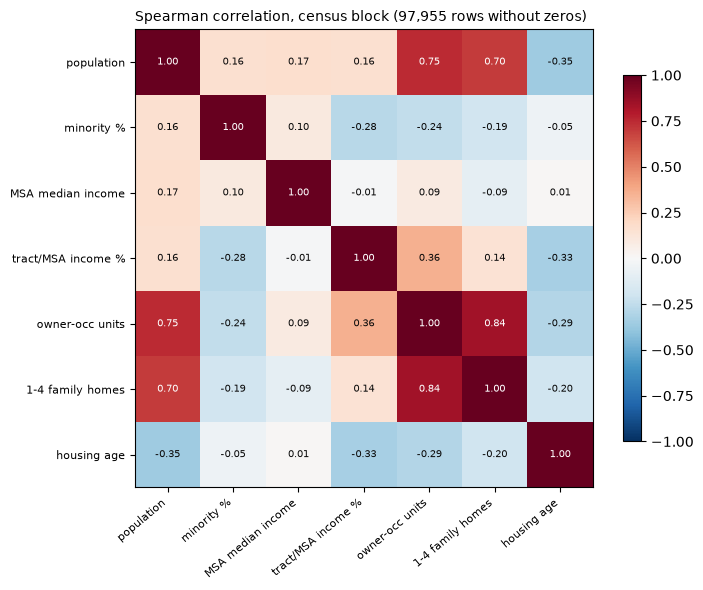

In [26]:
ok = (train[CENSUS] > 0).all(axis=1)
corr = train.loc[ok, CENSUS].corr(method="spearman")
short = ["population", "minority %", "MSA median income", "tract/MSA income %", "owner-occ units", "1-4 family homes", "housing age"]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)   # diverging: blue negative, red positive, white 0
ax.set_xticks(range(7), short, rotation=40, ha="right", fontsize=8); ax.set_yticks(range(7), short, fontsize=8)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f"Spearman correlation, census block ({ok.sum():,} rows without zeros)", loc="left", fontsize=10)
fig.tight_layout()

The three size variables (population, owner-occupied units, 1-4 family homes) are strongly correlated (0.70-0.84). Everything else is weakly related (|ρ| <0.36): minority %, MSA income and relative tract income carry separate information.

For the linear model, replace the size trio by ratios that remove size: owner-occupied share = owner-occupied / 1-4 family homes. Trees can keep all.

,PC1,PC2,PC3
population,0.50,0.38,-0.09
minority %,-0.16,0.67,-0.26
MSA median income,0.03,0.29,-0.44
tract/MSA income %,0.24,-0.54,-0.46
owner-occ units,0.57,-0.00,0.13
1-4 family homes,0.50,0.12,0.42
housing age,-0.29,0.07,0.57


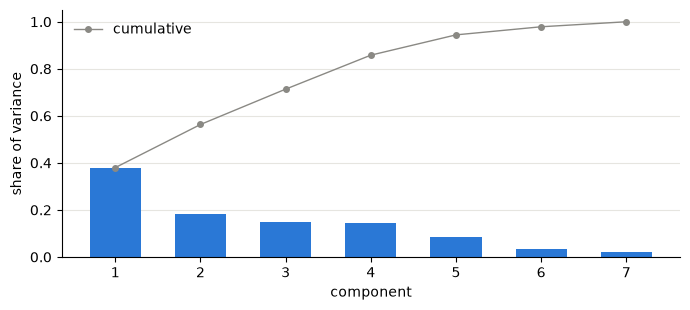

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
X = train.loc[ok, CENSUS].copy()
for c in ["tract_population", "tract_owner_occupied_units", "tract_one_to_four_family_homes", "ffiec_msa_md_median_family_income"]:
    X[c] = np.log(X[c])
pca = PCA().fit(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(1, 8), pca.explained_variance_ratio_, color=TRAIN_COLOR, width=0.6)
ax.plot(range(1, 8), pca.explained_variance_ratio_.cumsum(), "o-", color=MUTED, lw=1, ms=4, label="cumulative")
ax.set_xlabel("component"); ax.set_ylabel("share of variance"); ax.legend(frameon=False)
style(ax, "y"); fig.tight_layout()
pd.DataFrame(pca.components_[:3].T, index=short, columns=["PC1", "PC2", "PC3"]).round(2)

- PC1 (38%) is the size axis
- PC2 (18%) is minority % vs relative income
- 4 components are needed for 86%. 

The block is **not very compressible**: apart from the size trio, the variables are genuinely different.

No PCA features. They would save little and would make the fairness analysis harder, since a component mixes minority % with other variables.

Q. Do neighbourhood minority share and neighbourhood income relate to acceptance?
This matters twice: as signal, and as a **proxy for race**.

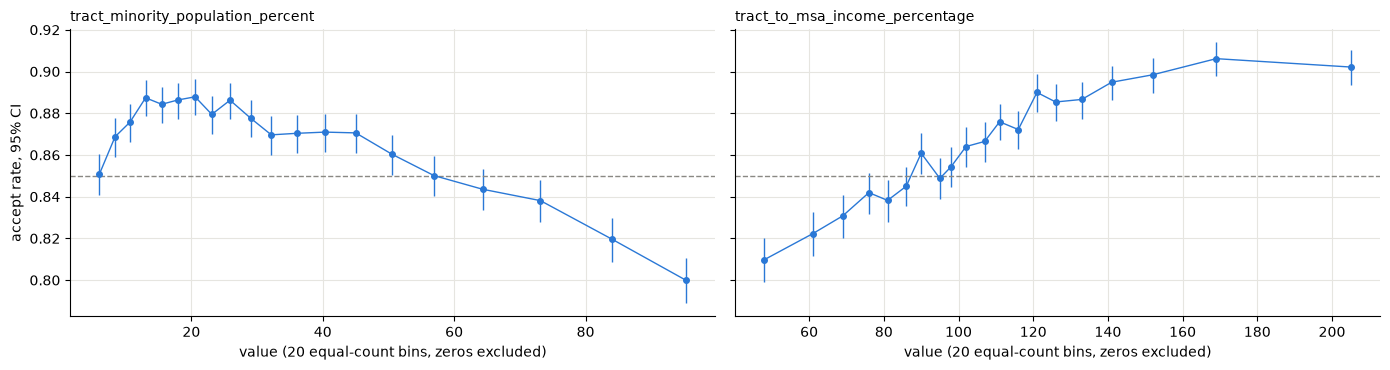

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, c in zip(axes, ["tract_minority_population_percent", "tract_to_msa_income_percentage"]):
    s = train[c].where(train[c] > 0)
    g = train.groupby(pd.qcut(s, 20, duplicates="drop"), observed=True).agg(x=(c, "median"), n=(TARGET, "size"), k=(TARGET, "sum"))
    lo, hi = wilson(g.k, g.n); r = g.k / g.n
    ax.errorbar(g.x, r, yerr=[r - lo, hi - r], fmt="o-", ms=4, lw=1, color=TRAIN_COLOR)
    ax.axhline(OVERALL, color=MUTED, ls="--", lw=1)
    ax.set_title(c, loc="left", fontsize=10); ax.set_xlabel("value (20 equal-count bins, zeros excluded)")
    style(ax, "both")
axes[0].set_ylabel("accept rate, 95% CI")
fig.tight_layout()

Relative tract income: acceptance rises steadily from 0.81 to 0.91. Minority %: rises until ~20%, then **falls to 0.80** in tracts with > 90% minority population.

Real signal, and a **proxy for race** (fairness): we must measure how well these neighbourhood features predict the applicant's race. Non-linear => splines for the linear model.

## Protected attributes

The target is a **lender's recorded decision**, not creditworthiness. Everything below describes associations in
that decision, not causes.

Q. how different are raw accept rates across race, ethnicity, sex and age?

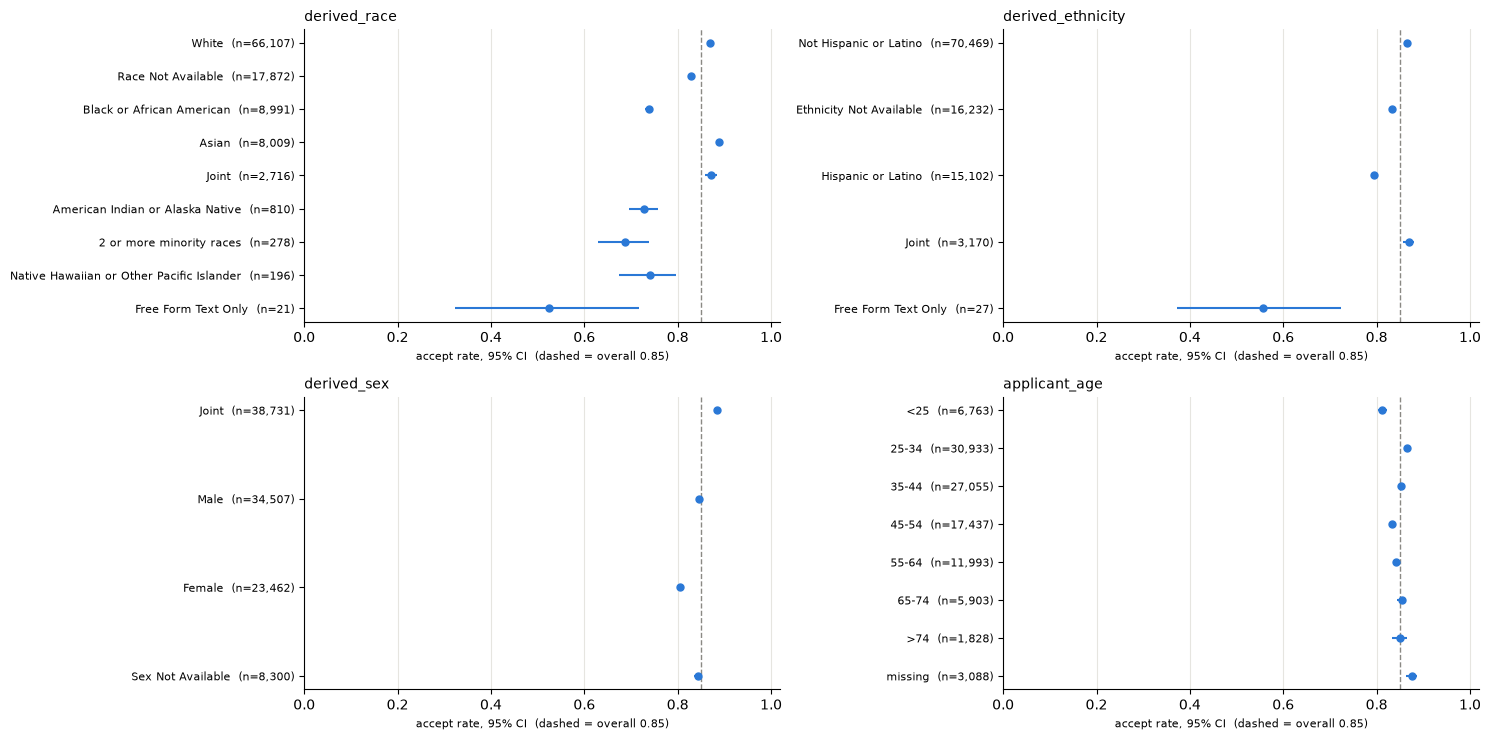

In [29]:
age_order = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74", "missing"]
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for ax, c in zip(axes.flat, ["derived_race", "derived_ethnicity", "derived_sex", "applicant_age"]):
    plot_rates(ax, rate_table(train[c]), c, order=age_order if c == "applicant_age" else None)
fig.tight_layout()

- Raw accept rates: Black 0.74
- American Indian 0.73
- 2+ minority races 0.69 vs White 0.87 and Asian 0.89. 
- Hispanic 0.79 vs non-Hispanic 0.87. 
- Female 0.81 vs male 0.85 vs joint 0.88. 
- Age: flat except < 25 (0.81). 
- "Not available" categories are large (race 17%, ethnicity 15%, sex 8%).

These are **raw** gaps in lender decisions, not evidence of their cause.

In [30]:
main = ["White", "Black or African American", "Asian", "Race Not Available", "American Indian or Alaska Native"]
d = train[train.derived_race.isin(main)].copy()
d["dti_over_50"] = d.debt_to_income_ratio.isin(["50%-60%", ">60%"])
d["no_aus"] = d["aus-1"] == "6"
d["fha_va_usda"] = d.loan_type != "1"
(d.groupby("derived_race", observed=True)
  .agg(n=(TARGET, "size"), accept_rate=(TARGET, "mean"), median_income_k=("income", "median"),
       median_loan=("loan_amount", "median"), median_ltv=("loan_to_value_ratio", "median"),
       share_dti_over_50=("dti_over_50", "mean"), share_no_aus=("no_aus", "mean"),
       share_gov_loan=("fha_va_usda", "mean"))
  .reindex(main).round(3))

,n,accept_rate,median_income_k,median_loan,median_ltv,share_dti_over_50,share_no_aus,share_gov_loan
derived_race,,,,,,,,
White,66107,0.868,105.0,275000.0,90.00,0.131,0.191,0.256
Black or African American,8991,0.739,85.0,255000.0,96.50,0.256,0.242,0.453
Asian,8009,0.889,151.0,405000.0,80.00,0.093,0.163,0.109
Race Not Available,17872,0.828,110.0,295000.0,85.55,0.145,0.309,0.234
American Indian or Alaska Native,810,0.727,79.0,220000.0,96.50,0.246,0.319,0.399


Groups differ strongly on financial variables. Black applicants: median income $85k vs $105k (White), median LTV 96.5 vs 90, **twice as often DTI > 50%** (25.6% vs 13.1%), government loans 45% vs 26%. Asian applicants: higher incomes and lower LTV.

Part of the raw gap runs through financial variables, so a model **without** race will still reproduce part of it. "Dropping race" is therefore not a fairness method by itself: section 12 must measure outcomes, not only inputs.

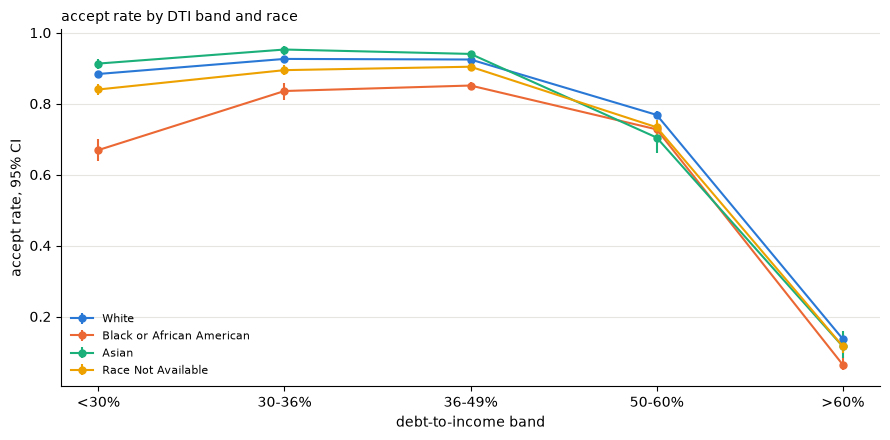

In [31]:
bands = {"<20%": "<30%", "20%-<30%": "<30%", "30%-<36%": "30-36%", "50%-60%": "50-60%", ">60%": ">60%"}
band = train.debt_to_income_ratio.astype("string").map(lambda v: bands.get(v, "36-49%"), na_action="ignore")
band_order = ["<30%", "30-36%", "36-49%", "50-60%", ">60%"]
races = ["White", "Black or African American", "Asian", "Race Not Available"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # validated categorical slots 1-4, fixed order
fig, ax = plt.subplots(figsize=(9, 4.5))
for r, col in zip(races, colors):
    m = train.derived_race == r
    g = train[m].groupby(band[m])[TARGET].agg(["sum", "size"]).reindex(band_order)
    lo, hi = wilson(g["sum"], g["size"]); p = g["sum"] / g["size"]
    ax.errorbar(range(5), p, yerr=[p - lo, hi - p], fmt="o-", ms=5, lw=1.5, color=col, label=r, capsize=0)
ax.set_xticks(range(5), band_order); ax.set_xlabel("debt-to-income band"); ax.set_ylabel("accept rate, 95% CI")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("accept rate by DTI band and race", loc="left", fontsize=10)
style(ax, "y"); fig.tight_layout()

In [32]:
RACE = {"1": "Am. Indian/Alaska Native", "2": "Asian", "3": "Black", "4": "Native Hawaiian/PI", "5": "White",
        "6": "not provided", "7": "not applicable", "8": "no co-applicant"}
app = train["applicant_race-1"].astype("string").map(lambda v: RACE.get(v, f"{v} (sub-group)"), na_action="ignore")
pd.crosstab(train.derived_race, app.fillna("missing"))

applicant_race-1,21 (sub-group),22 (sub-group),23 (sub-group),24 (sub-group),25 (sub-group),26 (sub-group),27 (sub-group),41 (sub-group),42 (sub-group),43 (sub-group),44 (sub-group),Am. Indian/Alaska Native,Asian,Black,Native Hawaiian/PI,White,missing,not applicable,not provided
derived_race,,,,,,,,,,,,,,,,,,,
2 or more minority races,1,1,2,1,0,0,14,0,0,0,0,138,70,41,1,9,0,0,0
American Indian or Alaska Native,0,0,0,0,0,0,0,0,0,0,0,808,0,0,0,2,0,0,0
Asian,760,103,87,9,40,56,188,0,0,0,0,0,6682,0,0,84,0,0,0
Black or African American,0,0,0,0,0,0,0,0,0,0,0,0,0,8990,0,1,0,0,0
Free Form Text Only,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,21,0,0
Joint,24,8,18,5,6,5,10,3,0,0,6,275,500,513,51,1292,0,0,0
Native Hawaiian or Other Pacific Islander,0,0,0,0,0,0,0,2,4,4,38,0,0,0,136,12,0,0,0
Race Not Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2918,14954
White,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,66107,0,0,0


"derived_race" is a deterministic summary of applicant and co-applicant race. "applicant_race-1" carries the same information at a finer level.

The 17 demographic columns are highly redundant. For the "no protected attributes" model , **all** of them must be removed together; removing one leaves the information in the others.

## J. Missingness and sentinel codes

In [33]:
is_1111 = pd.DataFrame({c: train[c].astype("string") == "1111" for c in CODED}).fillna(False)
per_row = is_1111.sum(axis=1)
display(rate_table(per_row)[["n", "share", "rate", "lo", "hi"]].round(3).rename_axis("# of 1111 codes in the row"))
cols = is_1111.columns[is_1111.any()]
print(f"{len(cols)} columns contain 1111:", list(cols))

,n,share,rate,lo,hi
# of 1111 codes in the row,,,,,
0,101984,0.971,0.848,0.846,0.850
1,30,0.000,0.967,0.833,0.994
10,2,0.000,0.500,0.095,0.905
11,2,0.000,1.000,0.342,1.000
12,15,0.000,0.933,0.702,0.988
13,14,0.000,1.000,0.785,1.000
14,2942,0.028,0.914,0.903,0.923
2,2,0.000,0.500,0.095,0.905
3,1,0.000,0.000,0.000,0.793


14 columns contain 1111: ['reverse_mortgage', 'open-end_line_of_credit', 'business_or_commercial_purpose', 'negative_amortization', 'interest_only_payment', 'balloon_payment', 'other_nonamortizing_features', 'manufactured_home_secured_property_type', 'manufactured_home_land_property_interest', 'applicant_credit_score_type', 'co-applicant_credit_score_type', 'submission_of_application', 'initially_payable_to_institution', 'aus-1']


2,942 rows carry 1111 in all 14 columns, and ~100 more in 1-13 of them. So "1111" is a property of the row (institution-level partial exemption), not of the field. Those rows are accepted at 0.91.

One row-level flag "is_exempt_record" + a count of 1111 per row, and keep "1111" as its own level in categoricals.

,missing_%,accept_if_missing,accept_if_present
loan_to_value_ratio,11.31,0.538,0.890
property_value,4.53,0.698,0.857
income,4.36,0.859,0.850
loan_term,3.15,0.872,0.849
county_code,1.28,0.246,0.858
state_code,0.78,0.100,0.856
debt_to_income_ratio,7.31,0.822,0.852
applicant_age,2.94,0.875,0.849
co-applicant_age,55.90,0.828,0.877


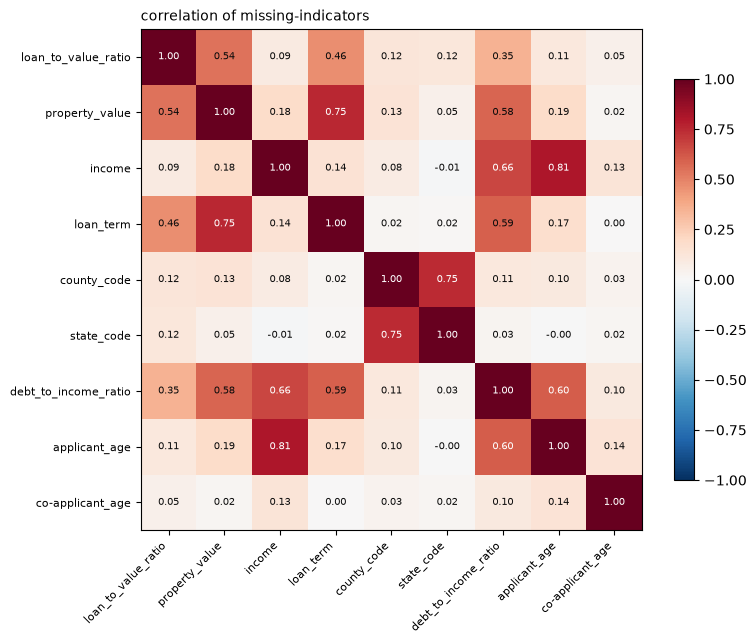

In [34]:
miss = train[FEATURES].isna()
cols = miss.columns[miss.mean() > 0.005]
c = miss[cols].astype(float).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(cols)), cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(c.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("correlation of missing-indicators", loc="left", fontsize=10)
fig.tight_layout()
pd.DataFrame({"missing_%": (100 * miss[cols].mean()).round(2),
              "accept_if_missing": [train.loc[miss[k], TARGET].mean().round(3) for k in cols],
              "accept_if_present": [train.loc[~miss[k], TARGET].mean().round(3) for k in cols]})

Missingness comes in **blocks**: 
- (i) income, applicant age, DTI go missing together (ρ 0.60-0.81): accept normal (~0.86), consistent with non-natural-person borrowers
- (ii) property value, loan term, LTV, DTI together (0.46-0.75): accept **low** (LTV missing => 0.54), consistent with files that stopped before appraisal
- (iii) state and county (0.75): #G.

Create one indicator per block rather than per column (fewer, more meaningful flags).

## K. Train vs test

In [35]:
from scipy.stats import ks_2samp
def distance(a, b, c):
    if c in NUMERIC:
        return ks_2samp(a[c].dropna(), b[c].dropna()).statistic
    p = a[c].astype("string").fillna("missing").value_counts(normalize=True)
    q = b[c].astype("string").fillna("missing").value_counts(normalize=True)
    return 0.5 * p.subtract(q, fill_value=0).abs().sum()

# Noise reference: the same distance between two random disjoint parts of train (45,000 vs 60,000 rows).
# With many rare levels (county) the distance is large even with NO shift, so only the excess over it counts.
perm = np.random.default_rng(0).permutation(len(train))   # seed 0: arbitrary, fixed for reproducibility
part_a, part_b = train.iloc[perm[:len(test)]], train.iloc[perm[len(test):]]
shift = pd.DataFrame([(c, "KS" if c in NUMERIC else "TVD", distance(train, test, c), distance(part_a, part_b, c))
                      for c in FEATURES], columns=["feature", "measure", "train_vs_test", "noise_reference"])
shift["excess"] = shift.train_vs_test - shift.noise_reference
shift.sort_values("excess", ascending=False).head(12).round(4)

,feature,measure,train_vs_test,noise_reference,excess
53,debt_to_income_ratio,TVD,0.0134,0.0087,0.0047
46,state_code,TVD,0.0177,0.0136,0.0041
1,loan_to_value_ratio,KS,0.0077,0.0040,0.0037
12,tract_median_age_of_housing_units,KS,0.0050,0.0024,0.0026
33,applicant_race-1,TVD,0.0073,0.0056,0.0017
13,loan_type,TVD,0.0021,0.0004,0.0017
42,initially_payable_to_institution,TVD,0.0033,0.0022,0.0012
48,derived_loan_product_type,TVD,0.0022,0.0010,0.0012
55,co-applicant_age,TVD,0.0048,0.0037,0.0011
3,income,KS,0.0041,0.0030,0.0011
